In [1]:
import os, json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
from src import Questions
import matplotlib.patches as mpatches


plt.rcParams.update({'font.size': 14})

In [2]:
# creating a dataframe of all of the annotator profiles
questions = Questions().get_questions()
SCORED_ANNOTATOR_DIR = "annotation_artefacts/final_annotator_objects"
RUN_NAME = "Qwen25_7B_Inst"
os.makedirs(SCORED_ANNOTATOR_DIR, exist_ok=True)


In [3]:
# making a raw scores (both characteristic and downstream) for each annotator
all_tasktype_df = {}

task_types = ['mt_and_summarization', 'syntaxes', 'knowledge_and_reasoning', 'semantics', 'qa_extraction']
for tt in task_types:
    downstream_score_df = []
    for annfilename in os.listdir(SCORED_ANNOTATOR_DIR):
        annotator_filepath = os.path.join(SCORED_ANNOTATOR_DIR, annfilename)
        with open(annotator_filepath, "r") as  ao:
            annotator_object = json.load(ao)
        
        downstream_scores = {}
        for question_key, values in annotator_object["answers"].items():
            if values["answer"] == None or questions[question_key]["question_type"] != tt:
                continue
            for qid, score_s in values["downstream_scores"][RUN_NAME].items():
                postfix = questions[question_key]["metrics"][0] # first metric entry is by convention default
                matching_keys = [k for k in score_s if k.endswith(f"{postfix}_score")]
                if not matching_keys:
                    raise ValueError(f"No key ends with '{postfix}' for qid {qid}")
                correct_key = matching_keys[0]
                downstream_scores[f"{qid}-sentence_type"] = values["sentence_type"]
                downstream_scores[f"{qid}-sentence_length"] = values["sentence_length"]
                downstream_scores[f"{qid}-sentence_grammaticality"] = values["grammaticality"]
                downstream_scores[correct_key] = score_s[correct_key]

        downstream_score_df.append({
            "id" : annotator_object["id"],
            **downstream_scores,
        })
    all_tasktype_df[tt] = pd.DataFrame(downstream_score_df)

/Users/rayendito/miniconda3/envs/pietorch/lib/python3.12/site-packages/scipy/stats/_distn_infrastructure.py:2027: RuntimeWarning: divide by zero encountered in divide
  x = np.asarray((x - loc)/scale, dtype=dtyp)


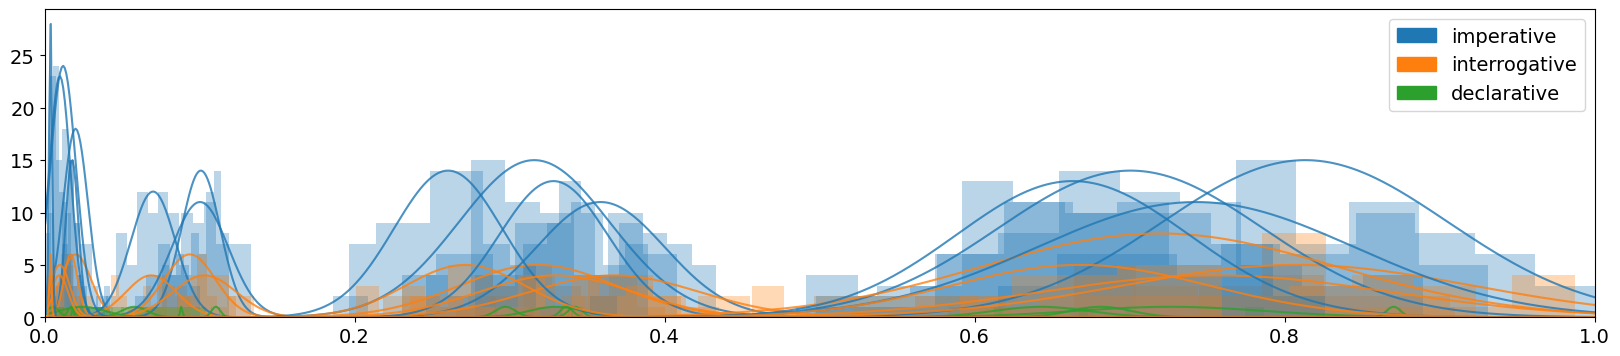

In [4]:
def collect_all_numbers(d):
    all_nums = []
    def recurse(x):
        if isinstance(x, dict):
            for v in x.values():
                recurse(v)
        elif isinstance(x, list):
            all_nums.extend(x)
    recurse(d)
    return all_nums

def normalize_nested_dict(d, min_val, max_val):
    def recurse(x):
        if isinstance(x, dict):
            for k, v in x.items():
                x[k] = recurse(v)
        elif isinstance(x, list):
            return [(i - min_val) / (max_val - min_val) if max_val != min_val else 0 for i in x]
        return x
    return recurse(d)

plt.figure(figsize=(20, 4))  # width=15, height=5        
plt.xlim(0, 1)
# propmt_sentence_type
characteristics_column = 0
task_group_histogram_data = {}
for tt in task_types:
    taskdf = all_tasktype_df[tt].drop(columns=['id'])
    cols = list(taskdf.columns)
    
    group_tasks_histogram_data = {}
    for i in range(0, len(cols), 4):
        chunk = cols[i:i+4]
        label_scores = {}
        for group_name, group_df in taskdf.groupby(chunk[characteristics_column]):
            label_scores[group_name] = group_df[chunk[-1]].tolist()
        
        task_code = chunk[0].split("-")[0]
        group_tasks_histogram_data[task_code] = label_scores

    all_nums = collect_all_numbers(group_tasks_histogram_data)
    min_val = min(all_nums)
    max_val = max(all_nums)
    task_group_histogram_data[tt] = normalize_nested_dict(group_tasks_histogram_data, min_val, max_val)
    break

# print(json.dumps(task_group_histogram_data, indent=4))
# Plot all as overlapping histograms
colors = {
    "imperative" : '#1f77b4',
    "interrogative" : '#ff7f0e',
    "declarative" : '#2ca02c',
}
for qdi, classifications in task_group_histogram_data['mt_and_summarization'].items():
    for label, score_list in classifications.items():
        counts, bin_edges, _ = plt.hist(score_list, bins=10, alpha=0.3, label=f'Data {i}', color=colors[label])
        
        mu, std = np.mean(score_list), np.std(score_list)
        x = np.linspace(0, 1, 1000)
        p = norm.pdf(x, mu, std)
        scale = max(counts) / np.max(p)

        # Get the current color used for the histogram
        color = plt.gca().patches[-1].get_facecolor()
        plt.plot(x, p * scale, color=color, alpha=0.8)


legend_patches = [mpatches.Patch(color=col, label=label) for label, col in colors.items()]
plt.legend(handles=legend_patches)

In [6]:
all_tasktype_df['syntaxes']

,id,16_0-sentence_type,16_0-sentence_length,16_0-sentence_grammaticality,Free Generation: Grammar Correction I-16_0-llm_judge_grammar_sentence_score,17_0-sentence_type,17_0-sentence_length,17_0-sentence_grammaticality,Free Generation: Grammar Correction II-17_0-llm_judge_score,19_0-sentence_type,...,27_2-sentence_grammaticality,Named Entity Recognition-ner_es-27_2-and_custom_score,27_1-sentence_type,27_1-sentence_length,27_1-sentence_grammaticality,Named Entity Recognition-ner_af-27_1-and_custom_score,27_0-sentence_type,27_0-sentence_length,27_0-sentence_grammaticality,Named Entity Recognition-ner_en-27_0-and_custom_score
0,34,imperative,14.0,correct,1.0,imperative,12.0,correct,0.8,imperative,...,correct,0.734367,imperative,37.0,correct,0.716016,imperative,37.0,correct,0.721794
1,63,imperative,9.0,correct,0.0,imperative,9.0,correct,0.5,imperative,...,correct,0.779765,imperative,55.0,correct,0.751734,imperative,55.0,correct,0.784176
2,75,interrogative,13.0,correct,1.0,imperative,23.0,correct,0.8,interrogative,...,correct,0.769260,imperative,58.0,correct,0.774948,imperative,58.0,correct,0.767831
3,22,interrogative,16.0,correct,1.0,imperative,18.0,correct,0.3,imperative,...,correct,0.749930,interrogative,51.0,correct,0.740698,interrogative,51.0,correct,0.764964
4,59,interrogative,10.0,correct,1.0,interrogative,15.0,correct,0.3,interrogative,...,incorrect,0.570406,interrogative,10.0,incorrect,0.576239,interrogative,10.0,incorrect,0.555462
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,37,imperative,13.0,correct,1.0,interrogative,23.0,correct,0.2,imperative,...,correct,0.803332,imperative,65.0,correct,0.805560,imperative,65.0,correct,0.820251
95,60,imperative,4.0,correct,1.0,imperative,5.0,correct,0.8,imperative,...,correct,0.691962,imperative,8.0,correct,0.660768,imperative,8.0,correct,0.689962
96,76,imperative,12.0,incorrect,0.0,imperative,32.0,correct,0.3,imperative,...,incorrect,0.623563,imperative,17.0,incorrect,0.633310,imperative,17.0,incorrect,0.651330
97,99,interrogative,36.0,correct,0.9,imperative,54.0,correct,0.9,imperative,...,correct,0.732766,imperative,64.0,correct,0.745660,imperative,64.0,correct,0.757376
